# Part 2: Building Footprint Segmentation (Inria Aerial Image Labeling)

**Author:** Md. Nadim Mahamood

End-to-end binary semantic segmentation (building vs. background) with **SegFormer-B3** (ImageNet-pretrained MiT-B3 encoder + 1-channel decoder head).

| Section | Content |
|---|---|
| 1 | Configuration |
| 2 | Data loading and **city-disjoint partitioning** with an automated **spatial-leakage audit** |
| 3 | Exploratory data analysis (EDA) |
| 4 | Dataset, patches and augmentation |
| 5 | Model and loss function (class imbalance + edge precision) |
| 6 | Training (optional; the saved checkpoint is loaded by default) |
| 7 | Evaluation: threshold chosen on validation, metrics beyond pixel accuracy, per-city/per-tile results, ROC/PR |
| 8 | Qualitative assessment: image | ground truth | prediction | error map (successes, failures, false alarms) |
| 9 | Whole-tile inference with overlapping windows and test-time augmentation (TTA) |
| 10 | Summary |

**How to run.** Set `DATA_ROOT` and `CHECKPOINT` in Section 1, then *Restart & Run All*. By default the notebook **loads the trained checkpoint** (`RUN_TRAINING = False`), so it finishes in minutes. Set `RUN_TRAINING = True` to train from scratch (hours on a GPU).

## 1. Configuration

In [3]:
import os, random, json, re, itertools
from pathlib import Path
from collections import defaultdict, OrderedDict

os.environ["OPENCV_LOG_LEVEL"] = "ERROR"
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import SegformerConfig, SegformerForSemanticSegmentation

# ------------------------------- paths -------------------------------
DATA_ROOT      = Path("AerialImageDataset")                      # contains train/images and train/gt
CHECKPOINT     = Path("outputs_city_split_segformer/best_val_iou.pt")   # trained model (best validation IoU)
TRAIN_OUT_DIR  = Path("outputs_notebook_training")               # used only if RUN_TRAINING = True
RESULTS_DIR    = Path("notebook_outputs")                        # figures / tables written here

# ------------------------------- experiment -------------------------------
SEED, PATCH, TILE = 99, 512, 5000
TRAIN_CITIES, VAL_CITY, TEST_CITY = ("austin", "chicago", "kitsap"), "vienna", "tyrol-w"
POS_WEIGHT = 5.92            # (1-p)/p for p = 0.144 building share in the training cities (see EDA)
BATCH_SIZE, NUM_WORKERS = 32, 4

# ------------------------------- switches -------------------------------
RUN_TRAINING = False         # True: train from scratch (long). False: load CHECKPOINT
EPOCHS, LR, PRETRAINED = 100, 5e-5, True
EVAL_TRAIN_SPLIT = True      # evaluate train, validation, and held-out test for the comparison figures
RUN_WHOLE_TILE_EVAL = True   # Section 9 (overlap + TTA)
TILE_LIMIT = 2               # number of test tiles used in the Section 9 demo (None = all 36; slow)
TILE_MODES = ["s512", "s256+tta4"]
BOUNDARY_DILATION, BOUNDARY_TOL = 3, 3   # pixels (0.3 m / px)

IMG_DIR, GT_DIR = DATA_ROOT / "train" / "images", DATA_ROOT / "train" / "gt"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device)

device: cuda


## 2. Data loading and city-disjoint partitioning

**Why not a random patch split?** Patches cut from the same 5000 x 5000 tile share neighbouring pixels, and buildings, roof materials and street layouts repeat inside a tile and inside a city. A random split would test the model on near-duplicates of its training data and overstate performance.

**Partitioning scheme (coded below).** The 180 labelled tiles (36 per city) are split **by city**:

| Split | Cities | Role |
|---|---|---|
| Train | Austin, Chicago, Kitsap | weight updates only |
| Validation | Vienna | checkpoint selection and decision-threshold tuning |
| Test | West Tyrol | final, held-out evaluation |

Patches are generated **after** the split, on a **non-overlapping** 512 x 512 grid. The official `test` folder has no public masks, so it cannot be scored and is not used.

In [4]:
def city_of(tile_id):
    return re.sub(r"\d+$", "", tile_id)          # "tyrol-w12" -> "tyrol-w"

def tile_ids_for_cities(cities):
    ids = []
    for city in cities:
        found = sorted(p.stem for p in IMG_DIR.glob(f"{city}*.tif"))
        if not found:
            raise FileNotFoundError(f"No tiles for {city!r} in {IMG_DIR}. Check DATA_ROOT.")
        ids.extend(found)
    return ids

ids_by_split = {
    "train": tile_ids_for_cities(TRAIN_CITIES),
    "val":   tile_ids_for_cities((VAL_CITY,)),
    "test":  tile_ids_for_cities((TEST_CITY,)),
}

def build_patch_index(tile_ids, patch_size=PATCH):
    """Non-overlapping grid covering every pixel of every tile (padded from 5000 to 5120)."""
    index = []
    for tile_id in tile_ids:
        with Image.open(IMG_DIR / f"{tile_id}.tif") as im:
            width, height = im.size
        assert (width, height) == (TILE, TILE), f"{tile_id}: unexpected size {(width, height)}"
        pw = ((width + patch_size - 1) // patch_size) * patch_size
        ph = ((height + patch_size - 1) // patch_size) * patch_size
        index += [(tile_id, x, y) for y in range(0, ph, patch_size) for x in range(0, pw, patch_size)]
    return index

patch_index = {name: build_patch_index(ids) for name, ids in ids_by_split.items()}

In [5]:
def audit_split(ids_by_split, patch_index):
    """Assertions that demonstrate the absence of spatial leakage."""
    names = list(ids_by_split)
    for a, b in itertools.combinations(names, 2):
        assert not set(ids_by_split[a]) & set(ids_by_split[b]), f"tile overlap: {a}/{b}"
    print("[OK] tile IDs are pairwise disjoint across train / val / test")

    cities = {n: sorted({city_of(t) for t in ids}) for n, ids in ids_by_split.items()}
    for a, b in itertools.combinations(names, 2):
        assert not set(cities[a]) & set(cities[b]), f"city overlap: {a}/{b}"
    print("[OK] cities are pairwise disjoint:", cities)

    for n in names:
        assert {t for t, _, _ in patch_index[n]} == set(ids_by_split[n]), f"{n}: patches reference foreign tiles"
        assert len(set(patch_index[n])) == len(patch_index[n]), f"{n}: duplicate patches"
        assert all(x % PATCH == 0 and y % PATCH == 0 for _, x, y in patch_index[n]), f"{n}: grid not aligned"
    print(f"[OK] every patch belongs to exactly one split and lies on a non-overlapping {PATCH}px grid")
    return cities

cities = audit_split(ids_by_split, patch_index)
summary = pd.DataFrame({
    "cities": {n: ", ".join(cities[n]) for n in ids_by_split},
    "tiles": {n: len(ids_by_split[n]) for n in ids_by_split},
    "patches": {n: len(patch_index[n]) for n in ids_by_split},
})
display(summary)

manifest = {
    n: {
        "cities": cities[n],
        "tiles": ids_by_split[n],
        "n_patches": len(patch_index[n])
    }
    for n in ids_by_split
}

# Export JSON
manifest_path = RESULTS_DIR / "split_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))

# Export as PNG figure
fig_path = RESULTS_DIR / "split_manifest.png"

fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

text = json.dumps(manifest, indent=2)
ax.text(
    0.02, 0.98, text,
    transform=ax.transAxes,
    fontsize=9,
    fontfamily="monospace",
    verticalalignment="top"
)

plt.savefig(fig_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)

print(f"Saved JSON: {manifest_path}")
print(f"Saved figure: {fig_path}")

(RESULTS_DIR / "split_manifest.json").write_text(json.dumps(
    {n: {"cities": cities[n], "tiles": ids_by_split[n], "n_patches": len(patch_index[n])} for n in ids_by_split}, indent=2))

[OK] tile IDs are pairwise disjoint across train / val / test
[OK] cities are pairwise disjoint: {'train': ['austin', 'chicago', 'kitsap'], 'val': ['vienna'], 'test': ['tyrol-w']}
[OK] every patch belongs to exactly one split and lies on a non-overlapping 512px grid


,cities,tiles,patches
train,"austin, chicago, kitsap",108,10800
val,vienna,36,3600
test,tyrol-w,36,3600


Saved JSON: notebook_outputs/split_manifest.json
Saved figure: notebook_outputs/split_manifest.png


3598

## 3. Exploratory data analysis

Two questions drive the modelling choices: **how imbalanced are the classes**, and **how much does building coverage vary between cities**? Building coverage is measured on 6 evenly spaced tiles per city (masks subsampled by 10 for speed).

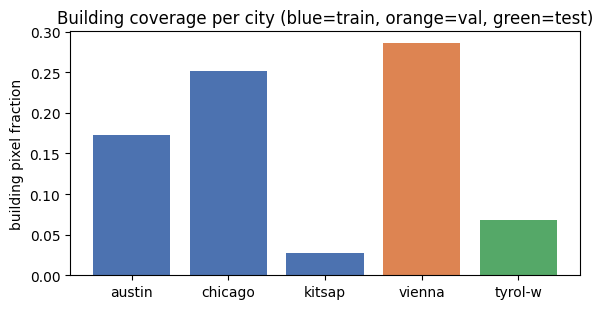

{'austin': 0.172, 'chicago': 0.252, 'kitsap': 0.027, 'vienna': 0.286, 'tyrol-w': 0.068}
training-city foreground p = 0.150  ->  background:building ~ 5.7 : 1
suggested BCE positive weight (1-p)/p = 5.65  (capped at 10; the trained model used 5.92)


In [6]:
def read_mask(tile_id):
    return cv2.imread(str(GT_DIR / f"{tile_id}.tif"), cv2.IMREAD_GRAYSCALE)

def read_image(tile_id):
    return cv2.cvtColor(cv2.imread(str(IMG_DIR / f"{tile_id}.tif"), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

all_cities = list(TRAIN_CITIES) + [VAL_CITY, TEST_CITY]
fg = {}
for city in all_cities:
    ids = [t for split in ids_by_split.values() for t in split if city_of(t) == city]
    sample = [ids[i] for i in np.linspace(0, len(ids) - 1, 6).astype(int)]
    fg[city] = float(np.mean([(read_mask(t)[::10, ::10] > 127).mean() for t in sample]))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(fg.keys(), fg.values(), color=["#4c72b0"] * 3 + ["#dd8452", "#55a868"])
ax.set_ylabel("building pixel fraction"); ax.set_title("Building coverage per city (blue=train, orange=val, green=test)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "eda_foreground_per_city.png", dpi=150); plt.show()

p_train = float(np.mean([fg[c] for c in TRAIN_CITIES]))
print({c: round(v, 3) for c, v in fg.items()})
print(f"training-city foreground p = {p_train:.3f}  ->  background:building ~ {(1 - p_train) / p_train:.1f} : 1")
print(f"suggested BCE positive weight (1-p)/p = {(1 - p_train) / p_train:.2f}  (capped at 10; the trained model used {POS_WEIGHT})")

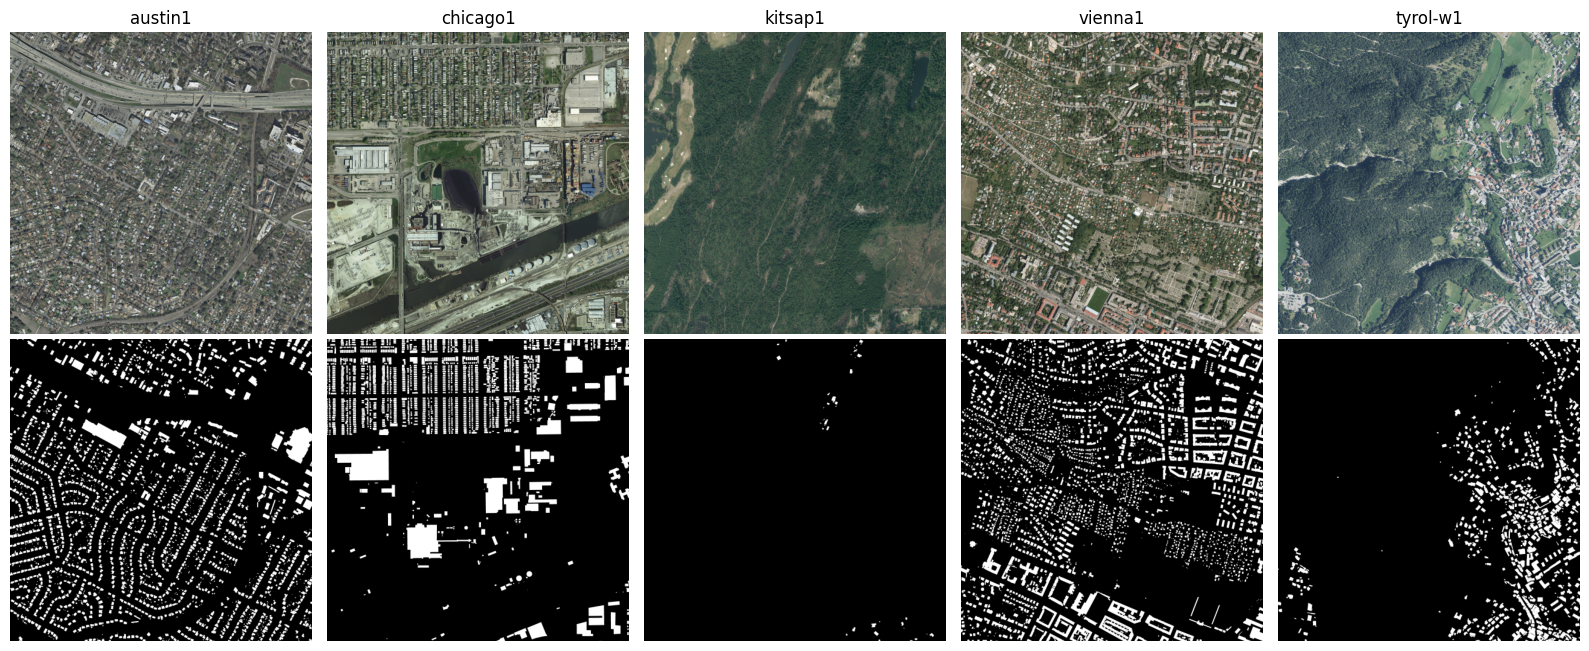

In [7]:
# One example tile per city: aerial image (top) and building mask (bottom), shown at 1/10 resolution
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
for col, city in enumerate(all_cities):
    tile_id = next(t for split in ids_by_split.values() for t in split if city_of(t) == city)
    image = cv2.resize(read_image(tile_id), (500, 500), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(read_mask(tile_id), (500, 500), interpolation=cv2.INTER_AREA)
    axes[0, col].imshow(image); axes[0, col].set_title(tile_id); axes[0, col].axis("off")
    axes[1, col].imshow(mask, cmap="gray"); axes[1, col].axis("off")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "eda_examples.png", dpi=120); plt.show()

**EDA takeaways.**
- Buildings cover only ~14% of training pixels (about 6 background pixels per building pixel), so plain cross-entropy would favour "background everywhere". The loss therefore uses a **positive-class weight** and a **Dice** term.
- Coverage varies from ~5% (Kitsap, West Tyrol) to ~29% (Vienna). Cities also differ in building size, density and roof colour, which is exactly why a **city-level** split is the honest test of generalisation.
- Pixel accuracy is dominated by background, so it is reported only for reference; **IoU, Dice, precision, recall and boundary metrics** are the real criteria.

## 4. Dataset, patches and augmentation

- **Patch size 512 x 512:** a 5000 x 5000 tile does not fit in GPU memory; 512 keeps context around buildings (about 150 m at 0.3 m/px) while allowing batches of 16.
- **Augmentation (train only):** flips and 90-degree rotations (aerial imagery has no canonical orientation), brightness/contrast jitter and light blur (illumination and sensor differences between cities).
- Padding: tile edges are padded to 5120 px (reflect for the image, zeros for the mask). Padded pixels are **excluded from every metric** below.

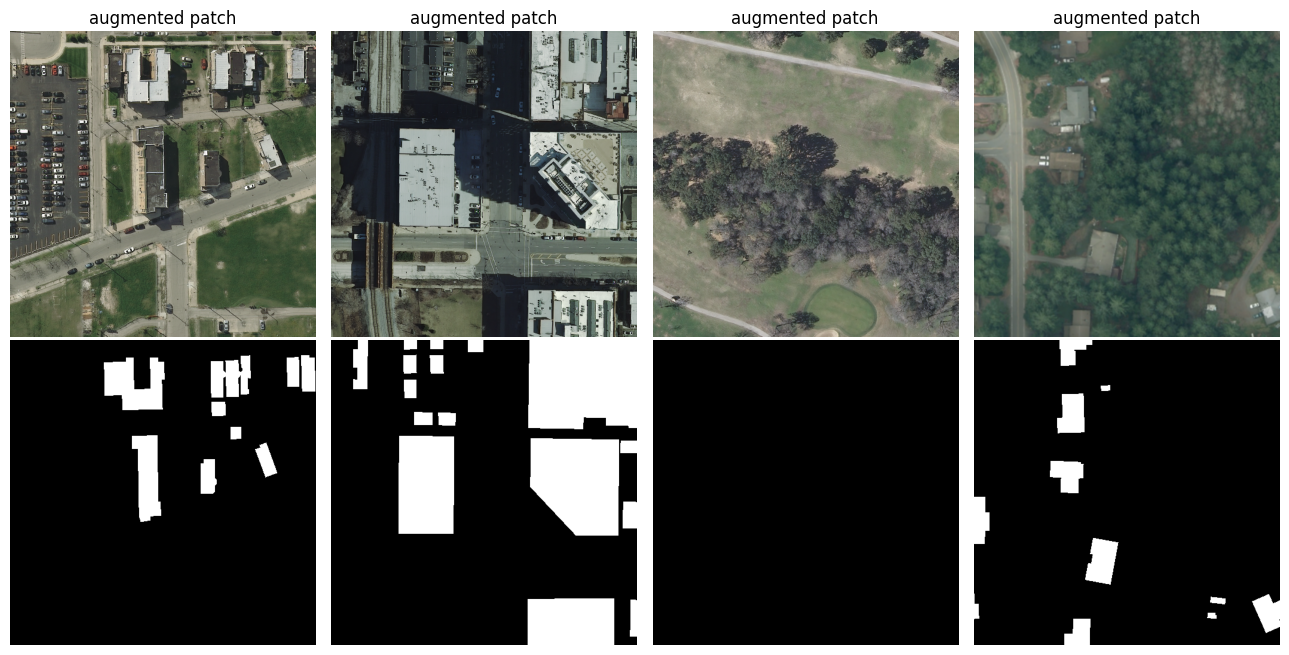

In [8]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class TileCache:
    def __init__(self, max_items=4):
        self.max_items, self.items = max_items, OrderedDict()
    def get(self, key, loader):
        if key in self.items:
            self.items.move_to_end(key); return self.items[key]
        self.items[key] = loader()
        if len(self.items) > self.max_items:
            self.items.popitem(last=False)
        return self.items[key]

class InriaPatches(Dataset):
    def __init__(self, patch_list, augment=False):
        self.patch_index, self.augment, self.cache = patch_list, augment, TileCache()
    def __len__(self):
        return len(self.patch_index)
    def _tile(self, tile_id):
        def load():
            return read_image(tile_id), read_mask(tile_id)
        return self.cache.get(tile_id, load)
    def __getitem__(self, i):
        tile_id, x, y = self.patch_index[i]
        image, mask = self._tile(tile_id)
        pad_b, pad_r = max(0, y + PATCH - image.shape[0]), max(0, x + PATCH - image.shape[1])
        if pad_b or pad_r:
            image = cv2.copyMakeBorder(image, 0, pad_b, 0, pad_r, cv2.BORDER_REFLECT_101)
            mask = cv2.copyMakeBorder(mask, 0, pad_b, 0, pad_r, cv2.BORDER_CONSTANT, value=0)
        image = image[y:y + PATCH, x:x + PATCH].copy()
        mask = (mask[y:y + PATCH, x:x + PATCH] > 127).astype(np.float32)
        if self.augment:
            image, mask = self._augment(image, mask)
        image = (image.astype(np.float32) / 255.0 - MEAN) / STD
        return torch.from_numpy(image.transpose(2, 0, 1)), torch.from_numpy(mask).unsqueeze(0)
    @staticmethod
    def _augment(image, mask):
        if random.random() < 0.5: image, mask = image[:, ::-1].copy(), mask[:, ::-1].copy()
        if random.random() < 0.5: image, mask = image[::-1].copy(), mask[::-1].copy()
        k = random.randrange(4)
        if k: image, mask = np.rot90(image, k).copy(), np.rot90(mask, k).copy()
        if random.random() < 0.3:
            image = cv2.convertScaleAbs(image, alpha=random.uniform(0.8, 1.2), beta=random.uniform(-20, 20))
        if random.random() < 0.2: image = cv2.GaussianBlur(image, (3, 3), 0)
        return image, mask

def denorm(t):
    return np.clip(t.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1)

train_ds = InriaPatches(patch_index["train"], augment=True)
val_ds   = InriaPatches(patch_index["val"])
test_ds  = InriaPatches(patch_index["test"])

# Sanity check: a few augmented training patches with their masks
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
for col, i in enumerate(random.sample(range(len(train_ds)), 4)):
    image, mask = train_ds[i]
    axes[0, col].imshow(denorm(image)); axes[0, col].axis("off"); axes[0, col].set_title("augmented patch")
    axes[1, col].imshow(mask[0], cmap="gray"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()

## 5. Model and loss function

### Architecture: SegFormer-B3
A hierarchical Mix-Transformer encoder (MiT-B3) with a light all-MLP decoder (47.2 M parameters, 1 output channel).
- **Multi-scale features** suit buildings that range from small sheds to large industrial roofs.
- **Self-attention** gives a large receptive field for context (shadows, road layout, roof continuity).
- **Transfer learning:** the encoder starts from **ImageNet-pretrained** weights and is fine-tuned end to end; the decoder head is randomly initialised. Pretraining helps because low-level features (edges, textures, colour) transfer well to aerial imagery and 108 training tiles are few for training a transformer from scratch.

### Loss: weighted BCE + Dice
`L = 0.5 * BCE_w + 0.5 * (1 - Dice)`
- **Class imbalance:** BCE uses a positive weight of 5.92 (see EDA); Dice is computed per image and is insensitive to the large background area.
- **Edge precision:** Dice penalises mismatched overlap directly, so edge pixels of small footprints matter more than under plain BCE. I also implemented an explicit **edge-zone BCE** (`BoundaryAwareLoss`, below) and tested it as a fine-tuning stage. It did **not** improve Vienna validation (best epoch IoU 0.745 / Boundary F1 0.585 vs. 0.759 / 0.594 for the starting checkpoint), so the reported model uses the original loss. Edge quality is instead measured with Boundary IoU / Boundary F1 and improved by overlapped, test-time-augmented inference (Section 9).

In [9]:
class SegformerWrapper(nn.Module):
    """Adapts the HuggingFace model to return {"out": logits at input resolution}."""
    def __init__(self, hf_model):
        super().__init__()
        self.hf_model = hf_model
    def forward(self, images):
        logits = self.hf_model(pixel_values=images).logits
        return {"out": F.interpolate(logits, size=images.shape[-2:], mode="bilinear", align_corners=False)}

def build_segformer(pretrained):
    if pretrained:   # ImageNet-pretrained encoder, randomly initialised 1-channel decoder head
        hf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b3", num_labels=1)
    else:            # architecture only (weights are loaded from the checkpoint); works offline
        try:
            cfg = SegformerConfig.from_pretrained("nvidia/mit-b3", num_labels=1)
        except Exception:
            cfg = SegformerConfig(num_labels=1, depths=[3, 4, 18, 3], hidden_sizes=[64, 128, 320, 512],
                                  num_attention_heads=[1, 2, 5, 8], sr_ratios=[8, 4, 2, 1], patch_sizes=[7, 3, 3, 3],
                                  strides=[4, 2, 2, 2], mlp_ratios=[4, 4, 4, 4], decoder_hidden_size=768)
        hf = SegformerForSemanticSegmentation(cfg)
    return SegformerWrapper(hf)

class DiceWeightedBCELoss(nn.Module):
    def __init__(self, pos_weight):
        super().__init__()
        self.register_buffer("pos_weight", torch.tensor([pos_weight], dtype=torch.float32))
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=self.pos_weight)
        p = torch.sigmoid(logits)
        inter = (p * targets).sum(dim=(1, 2, 3))
        denom = p.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
        dice_loss = 1.0 - (2.0 * inter + 1.0) / (denom + 1.0)
        return 0.5 * bce + 0.5 * dice_loss.mean()

In [10]:
# ---- boundary helpers (square structuring element, GPU max-pool based) ----
def erode(mask, r):  return -F.max_pool2d(-mask, 2 * r + 1, 1, r)
def dilate(mask, r): return F.max_pool2d(mask, 2 * r + 1, 1, r)
def boundary_band(mask, r): return mask * (1.0 - erode(mask, r))          # mask pixels within r px of the edge
def edge_zone(mask, r): return (dilate(mask, r) - erode(mask, r)).clamp(0.0, 1.0)   # +/- r px around the contour

class BoundaryAwareLoss(nn.Module):
    """Ablation: base loss + edge_weight * BCE averaged over the edge zone (tested as a fine-tuning stage)."""
    def __init__(self, base_loss, edge_weight=0.5, radius=3):
        super().__init__()
        self.base_loss, self.edge_weight, self.radius = base_loss, edge_weight, radius
    def forward(self, logits, targets):
        with torch.no_grad():
            zone = edge_zone(targets, self.radius)
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        return self.base_loss(logits, targets) + self.edge_weight * (bce * zone).sum() / (zone.sum() + 1.0)

## 6. Training (optional)

The reported checkpoint was trained with the same recipe (AdamW, lr 5e-5, weight decay 1e-4, ReduceLROnPlateau on validation IoU, mixed precision, batch 16, seed 99); the best validation IoU occurred at **epoch 17**. Training here saves a resumable checkpoint every epoch and selects the best epoch on the **validation city only**; the test city is never touched. Leave `RUN_TRAINING = False` to load the saved checkpoint instead.

In [11]:
def atomic_save(obj, path):
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "wb") as handle:
        torch.save(obj, handle); handle.flush(); os.fsync(handle.fileno())
    os.replace(tmp, path)

def run_epoch(net, loader, loss_fn, optimizer=None, scaler=None):
    training = optimizer is not None
    net.train(training)
    total, seen, counts = 0.0, 0, np.zeros(4)
    for images, masks in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        with torch.set_grad_enabled(training):
            with torch.amp.autocast("cuda", enabled=use_amp):
                logits = net(images)["out"]
            loss = loss_fn(logits.float(), masks)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        total += loss.item() * images.size(0); seen += images.size(0)
        pred = (torch.sigmoid(logits.detach().float()) >= 0.5).float()
        counts += [(pred * masks).sum().item(), (pred * (1 - masks)).sum().item(),
                   ((1 - pred) * masks).sum().item(), ((1 - pred) * (1 - masks)).sum().item()]
    tp, fp, fn, _ = counts
    return total / seen, tp / (tp + fp + fn + 1e-7)

def train_model():
    TRAIN_OUT_DIR.mkdir(parents=True, exist_ok=True)
    net = build_segformer(PRETRAINED).to(device)
    loss_fn = DiceWeightedBCELoss(POS_WEIGHT).to(device)
    optimizer = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=5)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, pin_memory=use_amp)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=use_amp)
    best_iou, start, history = -1.0, 1, []
    last_path, best_path = TRAIN_OUT_DIR / "last_checkpoint.pt", TRAIN_OUT_DIR / "best_val_iou.pt"
    if last_path.exists():                                   # resume after an interruption
        state = torch.load(last_path, map_location=device, weights_only=False)
        net.load_state_dict(state["model"]); optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"]); best_iou, history, start = state["best_iou"], state["history"], state["epoch"] + 1
        print(f"resuming at epoch {start}")
    for epoch in range(start, EPOCHS + 1):
        train_loss, train_iou = run_epoch(net, train_loader, loss_fn, optimizer, scaler)
        val_loss, val_iou = run_epoch(net, val_loader, loss_fn)
        scheduler.step(val_iou)
        history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss, train_iou=train_iou, val_iou=val_iou))
        print(f"epoch {epoch}/{EPOCHS}: train loss {train_loss:.4f} IoU {train_iou:.4f} | val loss {val_loss:.4f} IoU {val_iou:.4f}")
        if val_iou > best_iou:
            best_iou = val_iou
            atomic_save({"model": net.state_dict(), "epoch": epoch, "val_iou": val_iou}, best_path)
        atomic_save({"epoch": epoch, "model": net.state_dict(), "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict(), "best_iou": best_iou, "history": history}, last_path)
    return best_path

if RUN_TRAINING:
    CHECKPOINT = train_model()
    print("trained checkpoint:", CHECKPOINT)
else:
    print("RUN_TRAINING = False -> loading", CHECKPOINT)

RUN_TRAINING = False -> loading outputs_city_split_segformer/best_val_iou.pt


In [ ]:
if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT}. Set CHECKPOINT in Section 1 or set RUN_TRAINING = True.")
model = build_segformer(pretrained=False).to(device)
checkpoint = torch.load(CHECKPOINT, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model"])
model.eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"loaded {CHECKPOINT} (epoch {checkpoint.get('epoch', '?')}), parameters: {n_params:,} ({n_params / 1e6:.2f} M)")


# Learning curves from loss.csv
loss_file = Path("./losses.csv")

if loss_file.exists():
    hist = pd.read_csv(loss_file)

    print("Columns in loss.csv:", hist.columns.tolist())

    ep = hist["epoch"]

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

    for ax, keys, ylab in (
        (axes[0], ("train_loss", "val_loss"), "Loss"),
        (axes[1], ("train_iou", "val_iou"), "IoU"),
    ):
        for k in keys:
            if k in hist.columns:
                ax.plot(ep, hist[k], marker="o", ms=3, label=k)

        if "checkpoint" in globals() and "epoch" in checkpoint:
            ax.axvline(
                checkpoint["epoch"],
                color="k", ls="--", lw=1,
                label="selected epoch"
            )

        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylab)
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "learning_curves.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved: {RESULTS_DIR / 'learning_curves.png'}")
else:
    print(f"loss.csv not found: {loss_file}")

## 7. Evaluation

**Protocol.**
1. The model predicts a building probability for every patch of the **validation** (Vienna) and **test** (West Tyrol) cities.
2. The **decision threshold is chosen on Vienna only** (maximum IoU), then applied unchanged to the test city.
3. All metrics are pooled TP/FP/FN/TN counts over **real tile pixels only** (padding excluded):
   IoU, Dice/F1, precision, recall, pixel accuracy (reference only), **Boundary IoU** (IoU inside a 3-px band around each contour) and **Boundary F1** (contour precision/recall matched within a 3-px tolerance).
4. Results are reported pooled, **per city** and **per test tile**, plus threshold-independent ROC/PR curves.

In [ ]:
COLS = ["tp", "fp", "fn", "tn", "b_inter", "b_union", "bp_hit", "bp_sum", "br_hit", "br_sum"]

class IndexedPatches(Dataset):
    def __init__(self, base): self.base = base
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        image, mask = self.base[i]
        return image, mask, i

def valid_mask(patch_list, indices, patch_size):
    """1 for pixels inside the real 5000x5000 tile, 0 for padding."""
    valid = torch.zeros(len(indices), 1, patch_size, patch_size, device=device)
    for k, i in enumerate(indices.tolist()):
        _, x, y = patch_list[i]
        valid[k, :, : max(0, min(patch_size, TILE - y)), : max(0, min(patch_size, TILE - x))] = 1.0
    return valid

def gt_terms(masks, dilation=3, tolerance=3):
    band, contour = boundary_band(masks, dilation), boundary_band(masks, 1)
    return band, contour, dilate(contour, tolerance)

def confusion_and_boundary(preds, masks, valid=None, dilation=3, tolerance=3, gt=None):
    """(B, 10) tensor with columns COLS. preds/masks: (B,1,H,W) in {0,1}."""
    if valid is not None:
        preds = preds * valid
    gt_band, gt_contour, gt_contour_dilated = gt if gt is not None else gt_terms(masks, dilation, tolerance)
    d = (1, 2, 3)
    tp, fp, fn = (preds * masks).sum(d), (preds * (1 - masks)).sum(d), ((1 - preds) * masks).sum(d)
    neg = (1 - preds) * (1 - masks)
    tn = (neg * valid).sum(d) if valid is not None else neg.sum(d)
    pb, pc = boundary_band(preds, dilation), boundary_band(preds, 1)
    inter, union = (gt_band * pb).sum(d), (gt_band + pb - gt_band * pb).sum(d)
    return torch.stack([tp, fp, fn, tn, inter, union, (pc * gt_contour_dilated).sum(d), pc.sum(d),
                        (gt_contour * dilate(pc, tolerance)).sum(d), gt_contour.sum(d)], dim=1)

def summarize(row, eps=1e-7):
    tp, fp, fn, tn, bi, bu, bph, bps, brh, brs = [float(v) for v in row]
    bp, br = bph / (bps + eps), brh / (brs + eps)
    return {"iou": tp / (tp + fp + fn + eps), "dice": 2 * tp / (2 * tp + fp + fn + eps),
            "precision": tp / (tp + fp + eps), "recall": tp / (tp + fn + eps),
            "pixel_accuracy": (tp + tn) / (tp + fp + fn + tn + eps),
            "boundary_iou": bi / (bu + eps), "boundary_f1": 2 * bp * br / (bp + br + eps),
            "fg_fraction": (tp + fn) / (tp + fp + fn + tn + eps)}

@torch.no_grad()
def evaluate_patches(dataset, thresholds, record_thr=None, sample_pixels=0):
    """Per-tile statistics (n_thresholds x 10) for every threshold, plus optional pixel sample and per-patch records."""
    loader = DataLoader(IndexedPatches(dataset), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=use_amp)
    tile_stats = defaultdict(lambda: np.zeros((len(thresholds), 10)))
    budget = max(1, sample_pixels // max(len(loader), 1))
    ps, ls, records = [], [], []
    net = model.eval()
    for images, masks, idx in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        valid = valid_mask(dataset.patch_index, idx, PATCH)
        with torch.amp.autocast("cuda", enabled=use_amp):
            logits = net(images)["out"]
        probs = torch.sigmoid(logits.float())
        tiles = [dataset.patch_index[i][0] for i in idx.tolist()]
        if sample_pixels:
            inside = valid > 0
            p, l = probs[inside], masks[inside]
            keep = torch.randperm(p.numel(), device=device)[:budget]
            ps.append(p[keep].cpu().numpy()); ls.append(l[keep].cpu().numpy())
        gt = gt_terms(masks, BOUNDARY_DILATION, BOUNDARY_TOL)
        vfrac = valid.mean((1, 2, 3)).cpu().numpy()
        for t, thr in enumerate(thresholds):
            rows = confusion_and_boundary((probs >= thr).float(), masks, valid, BOUNDARY_DILATION, BOUNDARY_TOL, gt).cpu().numpy()
            for b, tile in enumerate(tiles):
                tile_stats[tile][t] += rows[b]
            if record_thr is not None and t == record_thr:
                for b, i in enumerate(idx.tolist()):
                    tp, fp, fn = rows[b][0], rows[b][1], rows[b][2]
                    records.append({"idx": i, "tile": tiles[b], "x": dataset.patch_index[i][1], "y": dataset.patch_index[i][2],
                                    "iou": tp / (tp + fp + fn + 1e-7), "fp": fp, "gt_frac": (tp + fn) / PATCH ** 2, "valid_frac": float(vfrac[b])})
    samples = (np.concatenate(ps), np.concatenate(ls)) if sample_pixels else None
    return {"tile_stats": dict(tile_stats), "samples": samples, "records": records}

def pooled(res, index, predicate=lambda tile: True):
    return np.sum([v[index] for t, v in res["tile_stats"].items() if predicate(t)], axis=0)

Threshold chosen on the validation city (max IoU): 0.85  (val IoU = 0.7592)


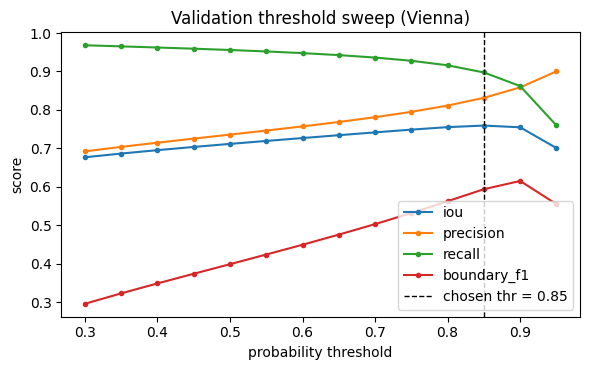

In [ ]:
# Step 1: validation sweep (Vienna) -> choose the threshold
GRID = [round(x, 2) for x in np.arange(0.30, 0.951, 0.05)]
val_res = evaluate_patches(val_ds, GRID, sample_pixels=2_000_000)
val_metrics = [summarize(pooled(val_res, i)) for i in range(len(GRID))]
best_i = int(np.argmax([m["iou"] for m in val_metrics]))
BEST_THR = GRID[best_i]
print(f"Threshold chosen on the validation city (max IoU): {BEST_THR:.2f}  (val IoU = {val_metrics[best_i]['iou']:.4f})")

fig, ax = plt.subplots(figsize=(6, 3.8))
for key in ("iou", "precision", "recall", "boundary_f1"):
    ax.plot(GRID, [m[key] for m in val_metrics], marker="o", ms=3, label=key)
ax.axvline(BEST_THR, color="k", ls="--", lw=1, label=f"chosen thr = {BEST_THR:.2f}")
ax.set_xlabel("probability threshold"); 
ax.set_ylabel("score"); 
ax.set_title("Validation threshold sweep (Vienna)"); 
ax.legend()
plt.tight_layout(); 
plt.savefig(RESULTS_DIR / "threshold_sweep_val.png", dpi=150); plt.show()

In [ ]:
# Step 2: train, validation and held-out test at thr=0.5 and at the validation-chosen threshold
THRS = sorted({0.5, BEST_THR})
BI = THRS.index(BEST_THR)
test_res = evaluate_patches(test_ds, THRS, record_thr=BI, sample_pixels=2_000_000)
results = {"val": (val_res, GRID), "test": (test_res, THRS)}
if EVAL_TRAIN_SPLIT:
    train_eval_ds = InriaPatches(patch_index["train"])          # no augmentation for evaluation
    results = {"train": (evaluate_patches(train_eval_ds, THRS, sample_pixels=2_000_000), THRS), **results}

def table_at(threshold):
    rows = []
    for split, (res, grid) in results.items():
        i = grid.index(threshold)
        rows.append({"split": split, "scope": "overall", **summarize(pooled(res, i))})
        for city in sorted({city_of(t) for t in res["tile_stats"]}):
            rows.append({"split": split, "scope": city, **summarize(pooled(res, i, lambda t, c=city: city_of(t) == c))})
    return pd.DataFrame(rows).set_index(["split", "scope"])

show_cols = ["iou", "dice", "precision", "recall", "pixel_accuracy", "boundary_iou", "boundary_f1", "fg_fraction"]
print(f"=== Results at the validation-chosen threshold ({BEST_THR:.2f}) ===")
table_best = table_at(BEST_THR); display(table_best[show_cols].round(4))
print("=== Results at the default threshold (0.5) ===")
table_half = table_at(0.5); display(table_half[show_cols].round(4))
table_best.to_csv(RESULTS_DIR / "metrics_thr_best.csv"); 
table_half.to_csv(RESULTS_DIR / "metrics_thr_0.5.csv")

error: Caught error in DataLoader worker process 2.
Original Traceback (most recent call last):
  File "/home/thor/anaconda3/envs/cardio/lib/python3.10/site-packages/torch/utils/data/_utils/worker.py", line 349, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
  File "/home/thor/anaconda3/envs/cardio/lib/python3.10/site-packages/torch/utils/data/_utils/fetch.py", line 52, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
  File "/home/thor/anaconda3/envs/cardio/lib/python3.10/site-packages/torch/utils/data/_utils/fetch.py", line 52, in <listcomp>
    data = [self.dataset[idx] for idx in possibly_batched_index]
  File "/tmp/ipykernel_36077/2999018527.py", line 7, in __getitem__
    image, mask = self.base[i]
  File "/tmp/ipykernel_36077/3579628914.py", line 26, in __getitem__
    image, mask = self._tile(tile_id)
  File "/tmp/ipykernel_36077/3579628914.py", line 23, in _tile
    return self.cache.get(tile_id, load)
  File "/tmp/

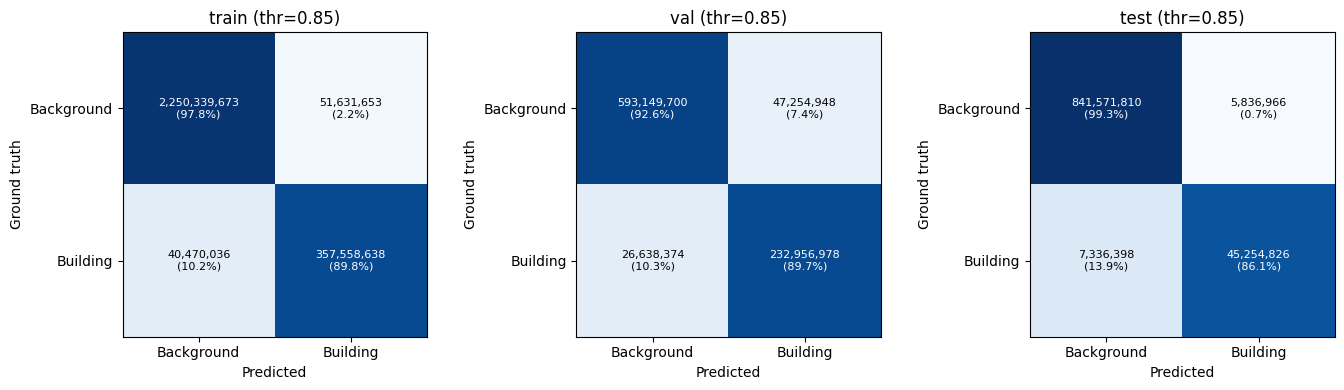

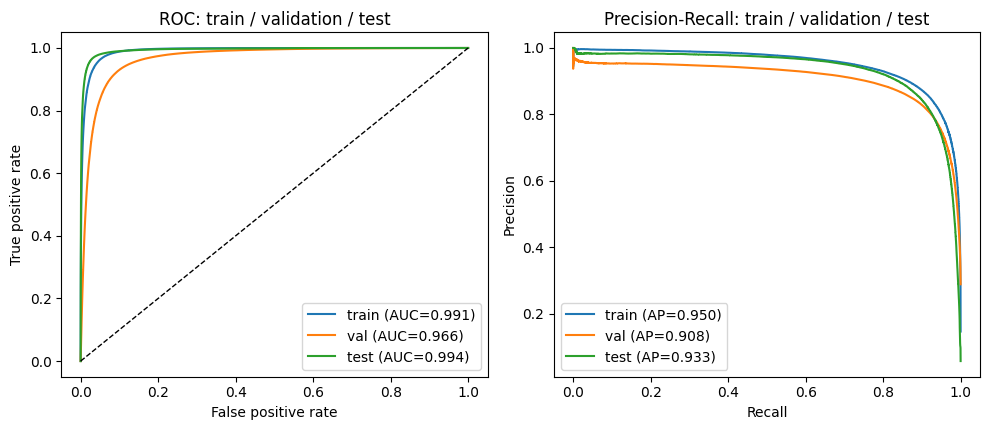

Threshold-independent pixel-level metrics for train, validation and held-out test sets:


,roc_auc,average_precision
split,,
train,0.9909,0.9503
val,0.9664,0.9077
test,0.9938,0.9332


In [ ]:
# Confusion matrices at the chosen threshold
fig, axes = plt.subplots(1, len(results), figsize=(4.6 * len(results), 4))
for ax, (split, (res, grid)) in zip(np.atleast_1d(axes), results.items()):
    tp, fp, fn, tn = pooled(res, grid.index(BEST_THR))[:4]
    m = np.array([[tn, fp], [fn, tp]]); norm = m / m.sum(1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 1], ["Background", "Building"]); ax.set_yticks([0, 1], ["Background", "Building"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth"); ax.set_title(f"{split} (thr={BEST_THR:.2f})")
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{int(m[r, c]):,}\n({norm[r, c]:.1%})", ha="center", va="center", fontsize=8, color="white" if norm[r, c] > 0.5 else "black")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150); plt.show()

# ROC and Precision-Recall curves for train, validation and held-out test pixels
curve_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for split, (res, _) in results.items():
    if res["samples"] is None:
        continue
    probs, labels = res["samples"]
    fpr, tpr, _ = roc_curve(labels, probs); precision, recall, _ = precision_recall_curve(labels, probs)
    roc_auc = auc(fpr, tpr)
    average_precision = average_precision_score(labels, probs)
    curve_rows.append({"split": split, "roc_auc": roc_auc, "average_precision": average_precision})
    axes[0].plot(fpr, tpr, label=f"{split} (AUC={roc_auc:.3f})")
    axes[1].plot(recall, precision, label=f"{split} (AP={average_precision:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC: train / validation / test")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall: train / validation / test")
for ax in axes: ax.legend()
plt.tight_layout(); plt.savefig(RESULTS_DIR / "roc_pr_train_val_test.png", dpi=150); plt.show()

curve_metrics = pd.DataFrame(curve_rows).set_index("split")
print("Threshold-independent pixel-level metrics for train, validation and held-out test sets:")
display(curve_metrics.round(4))
curve_metrics.to_csv(RESULTS_DIR / "roc_pr_metrics_train_val_test.csv")

In [ ]:
# Per-tile variation on the test city (is the pooled number driven by a few tiles?)
per_tile = pd.DataFrame([{"tile": t, **summarize(v[BI])} for t, v in sorted(test_res["tile_stats"].items())]).set_index("tile")
display(per_tile[["iou", "dice", "boundary_iou", "boundary_f1", "fg_fraction"]].agg(["mean", "std", "min", "max"]).round(4))
per_tile.to_csv(RESULTS_DIR / "per_tile_test_metrics.csv")

,iou,dice,boundary_iou,boundary_f1,fg_fraction
mean,0.7757,0.8733,0.2959,0.7796,0.0584
std,0.0338,0.0217,0.0346,0.0351,0.0378
min,0.6699,0.8023,0.2213,0.6993,0.0099
max,0.8600,0.9247,0.3774,0.8526,0.1792


## 8. Qualitative assessment

Each row shows the **aerial patch**, the **ground-truth mask**, the **predicted mask** and an **error map** (green = true positive, red = false positive, blue = false negative) from the held-out test city. Patches are picked **automatically** rather than by eye, using fully valid 512 x 512 patches (at most one per tile so the examples are diverse):
- **Successes:** highest patch IoU among patches with at least 5% building coverage.
- **Failures:** lowest patch IoU among the same candidates.
- **False alarms:** patches with the most predicted-building pixels where the ground truth has under 0.5% coverage.

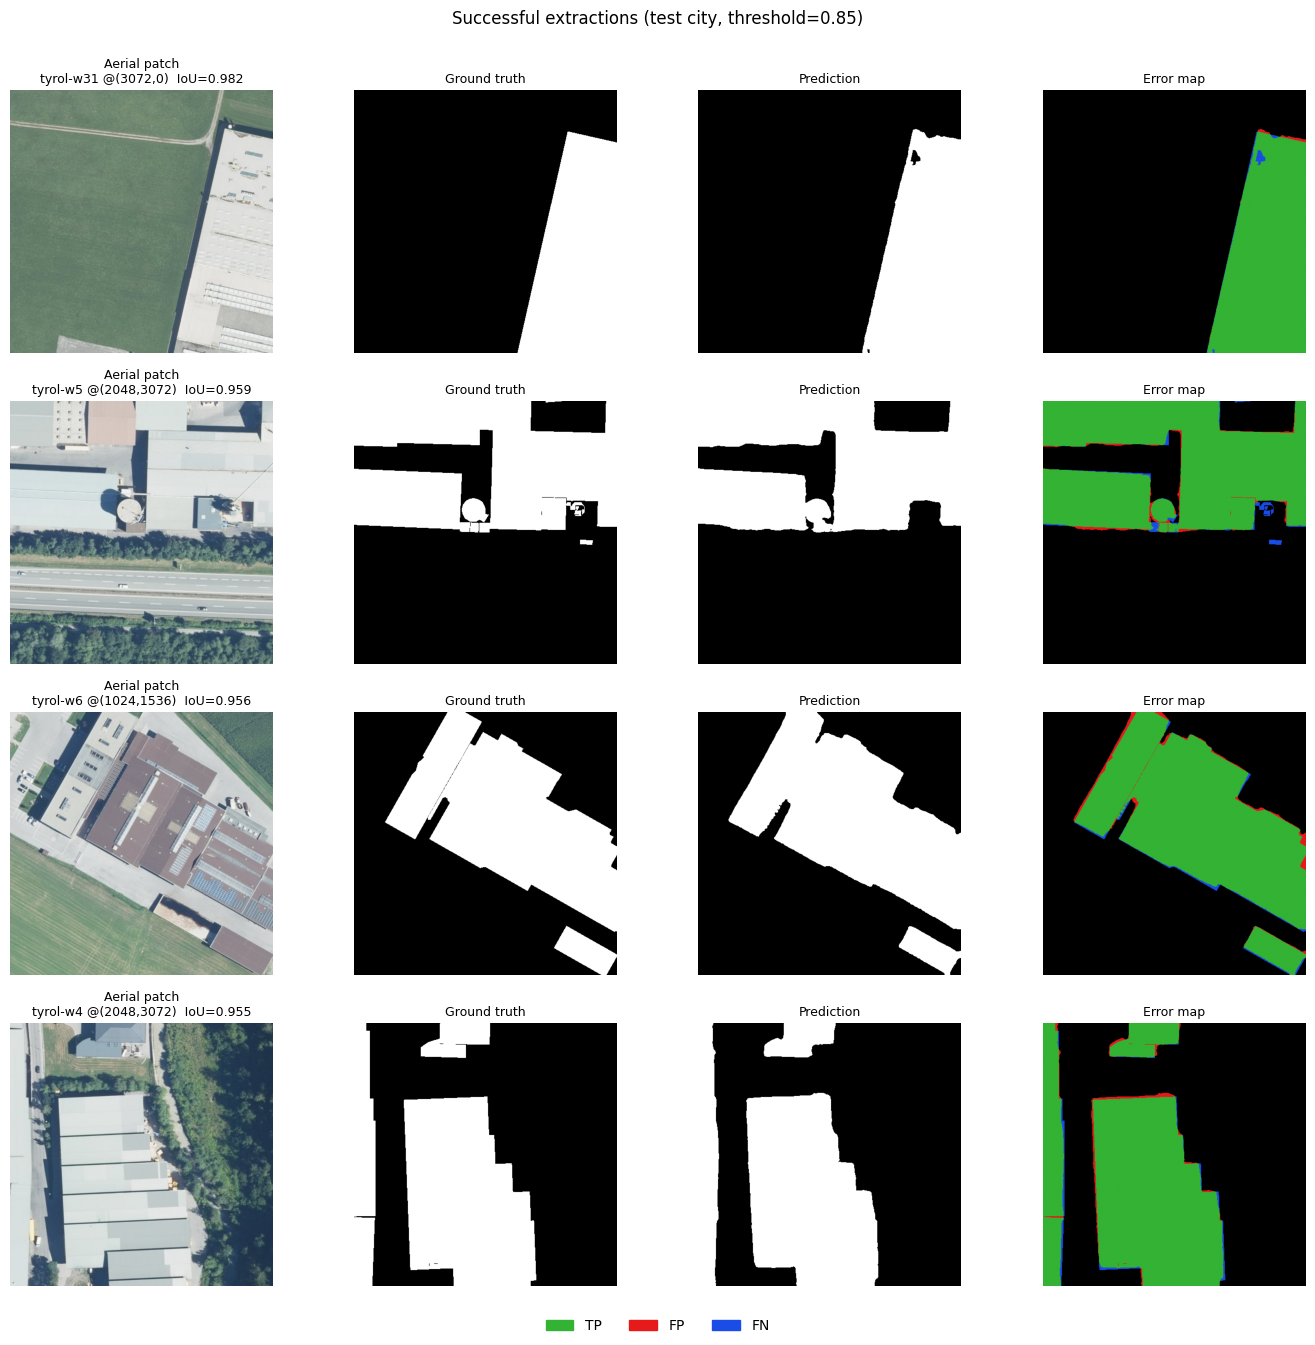

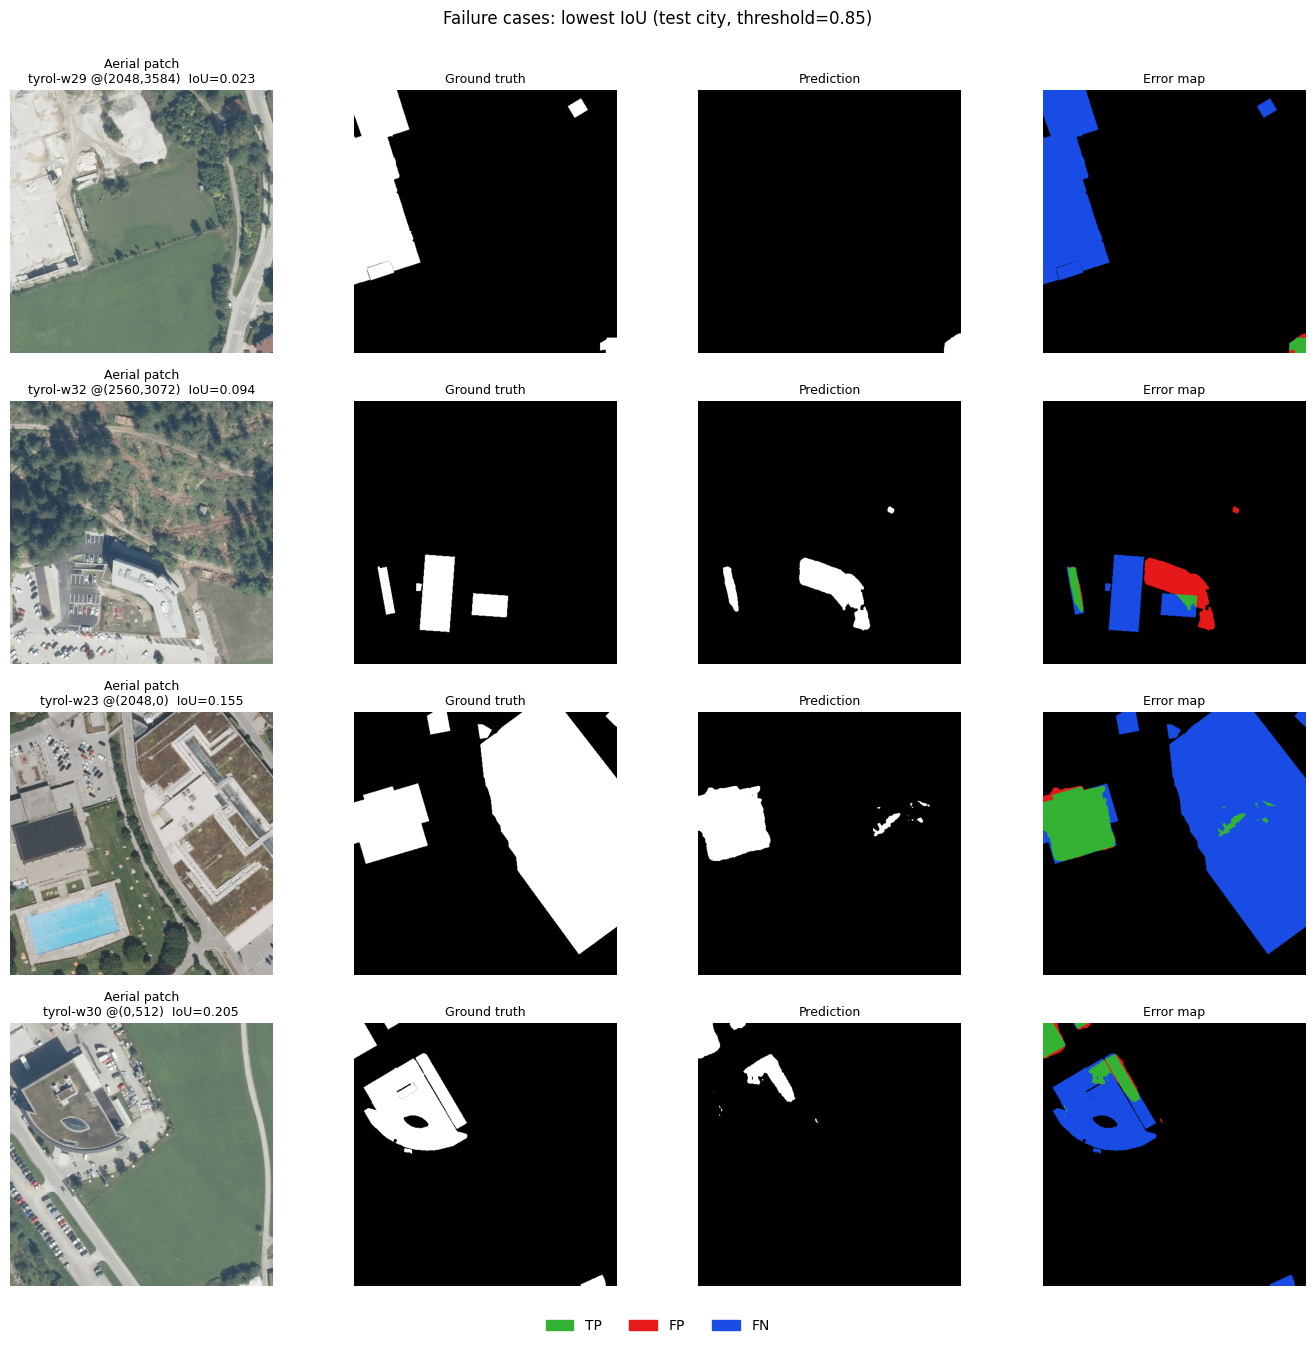

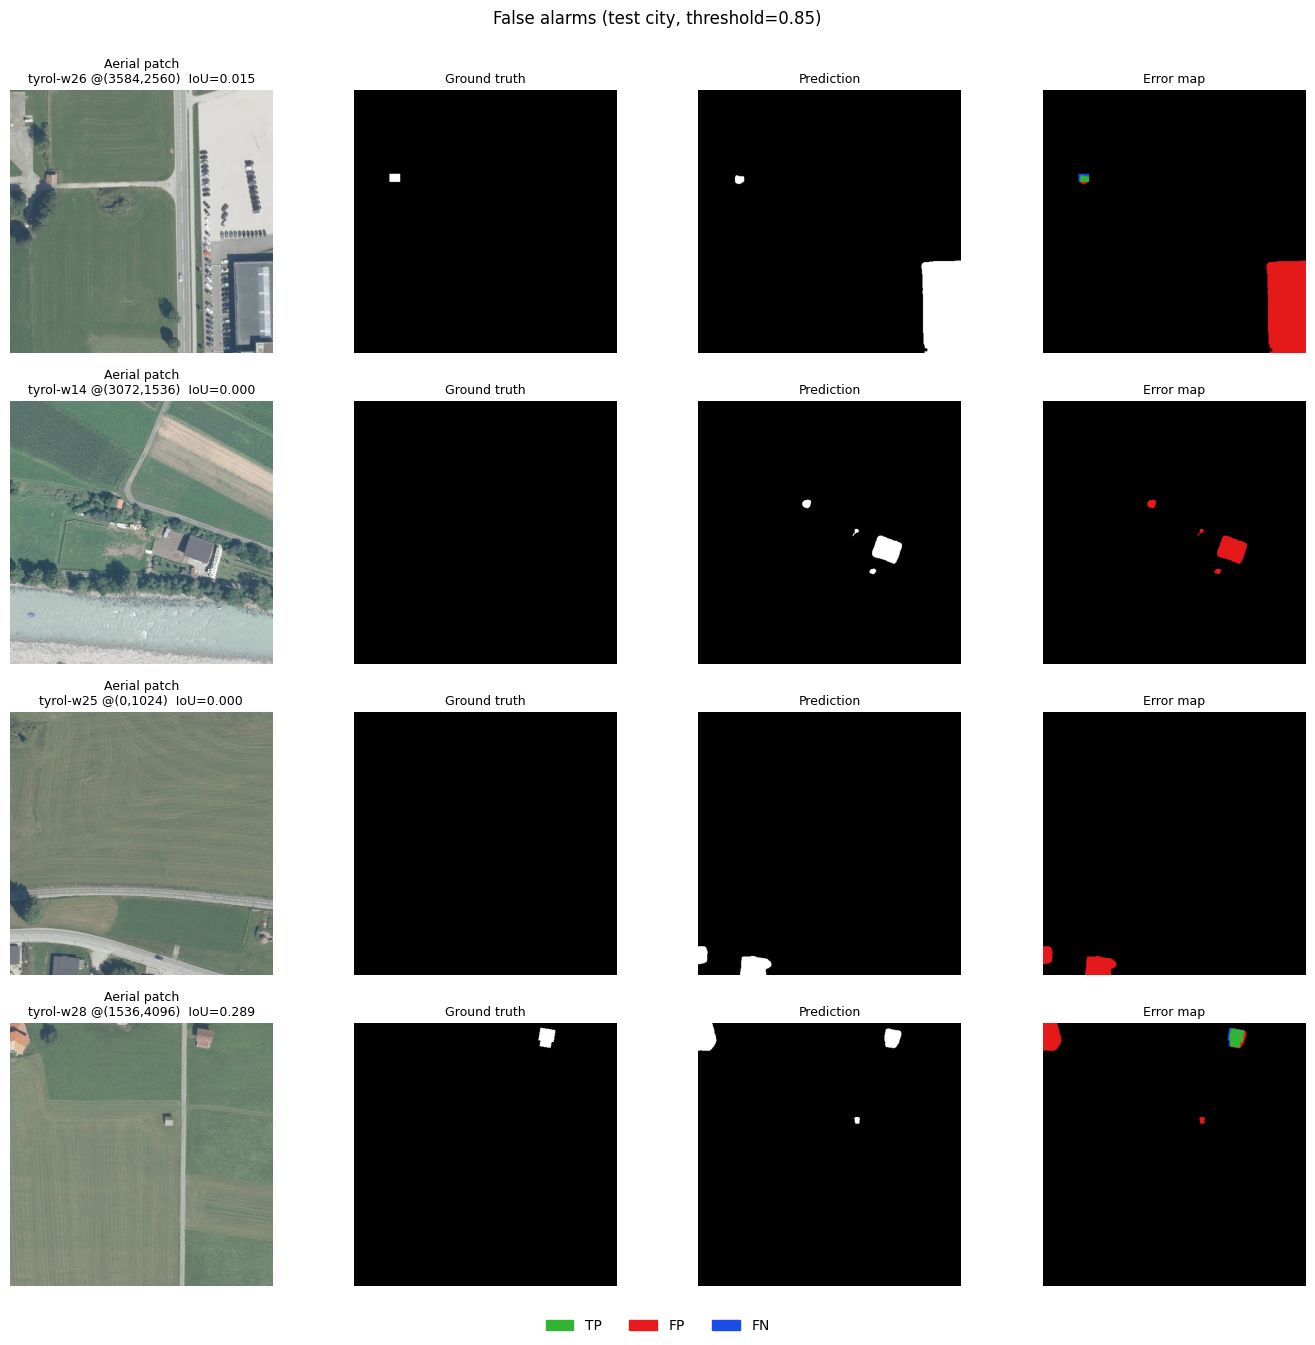

In [ ]:
def pick(records, key, k, descending):
    chosen, used = [], set()
    for r in sorted(records, key=key, reverse=descending):
        if r["tile"] in used: continue
        chosen.append(r); used.add(r["tile"])
        if len(chosen) == k: break
    return chosen

@torch.no_grad()
def render_examples(dataset, recs, title, filename):
    if not recs:
        print(f"no candidates for: {title}"); return
    fig, axes = plt.subplots(len(recs), 4, figsize=(14, 3.4 * len(recs)), squeeze=False)
    for row, rec in enumerate(recs):
        image, mask = dataset[rec["idx"]]
        prob = torch.sigmoid(model(image.unsqueeze(0).to(device))["out"].float())[0, 0].cpu().numpy()
        pred, truth = prob >= BEST_THR, mask[0].numpy() > 0.5
        err = np.zeros((*truth.shape, 3))
        err[truth & pred], err[~truth & pred], err[truth & ~pred] = (0.2, 0.7, 0.2), (0.9, 0.1, 0.1), (0.1, 0.3, 0.9)
        for col, (data, name) in enumerate([(denorm(image), "Aerial patch"), (truth, "Ground truth"), (pred, "Prediction"), (err, "Error map")]):
            axes[row, col].imshow(data, cmap=None if data.ndim == 3 else "gray"); axes[row, col].axis("off")
            axes[row, col].set_title(name if col else f"{name}\n{rec['tile']} @({rec['x']},{rec['y']})  IoU={rec['iou']:.3f}", fontsize=9)
    fig.legend(handles=[Patch(color=(0.2, 0.7, 0.2), label="TP"), Patch(color=(0.9, 0.1, 0.1), label="FP"), Patch(color=(0.1, 0.3, 0.9), label="FN")],
               loc="lower center", ncol=3, frameon=False)
    fig.suptitle(f"{title} (test city, threshold={BEST_THR:.2f})")
    fig.tight_layout(rect=(0, 0.03, 1, 0.98)); fig.savefig(RESULTS_DIR / filename, dpi=150); plt.show()

records = [r for r in test_res["records"] if r["valid_frac"] == 1.0]
candidates = [r for r in records if r["gt_frac"] >= 0.05]
K = 4
render_examples(test_ds, pick(candidates, lambda r: r["iou"], K, True), "Successful extractions", "qualitative_success.png")
render_examples(test_ds, pick(candidates, lambda r: r["iou"], K, False), "Failure cases: lowest IoU", "qualitative_failure.png")
render_examples(test_ds, pick([r for r in records if r["gt_frac"] < 0.005], lambda r: r["fp"], K, True), "False alarms", "qualitative_false_alarm.png")

**Observations (from the full run; verify against the figures above).**
- **Successes:** roofs whose colour contrasts with the surrounding vegetation and buildings with clear, straight edges; predicted boundaries follow these edges closely and the error maps are mostly green.
- **Failures:** bright or white non-building surfaces (pale ground, roads with white markings) confused with roofs (red), and low-contrast scenes with pale or no vegetation where roof and ground look alike (blue).
- **False alarms:** very small objects and non-green (bare) fields predicted as buildings. Possible future work: a detection-plus-prompting stage (e.g. YOLO to locate small objects and SAM to delineate them).

## 9. Whole-tile inference: overlapping windows and test-time augmentation (TTA)

Patch-wise prediction can leave seams at window borders and scores contours cut by a window edge inconsistently. Here whole 5000 x 5000 tiles are predicted with:
- **s512:** non-overlapping 512 px windows (as in training),
- **s256:** 50% overlap with smooth sine-ramp blending,
- **s256+tta4:** overlap plus **test-time augmentation (TTA)**: four views (identity, horizontal flip, vertical flip, 180-degree rotation) whose probabilities are averaged.

The threshold stays at the value chosen on Vienna. To keep this notebook fast it is evaluated on the first `TILE_LIMIT` test tiles; the full 36-tile results (test IoU 0.7745 / 0.7774 / 0.7750 and Boundary F1 0.7758 / 0.7839 / 0.7872 for s512 / s256 / s256+tta4) are reported in the paper. Set `TILE_LIMIT = None` to reproduce them (long).

In [ ]:
def _views(tta):
    if tta == "none": return [(0, False)]
    if tta == "tta4": return [(0, False), (0, True), (2, False), (2, True)]
    if tta == "tta8": return [(k, f) for k in range(4) for f in (False, True)]
    raise ValueError(tta)

def _predict_batch(batch, tta):
    total, views = 0.0, _views(tta)
    for k, flip in views:
        x = torch.rot90(torch.flip(batch, dims=(3,)) if flip else batch, k, dims=(2, 3))
        with torch.amp.autocast("cuda", enabled=use_amp):
            logits = model(x)["out"]
        y = torch.rot90(torch.sigmoid(logits.float()), -k, dims=(2, 3))
        total = total + (torch.flip(y, dims=(3,)) if flip else y)
    return total / len(views)

@torch.no_grad()
def predict_tile(image, stride=256, tta="none", batch_size=8):
    """Probability map (H, W) for a whole tile using overlapping windows with smooth blending."""
    model.eval()
    h, w = image.shape[:2]
    n_y = 1 if h <= PATCH else -(-(h - PATCH) // stride) + 1
    n_x = 1 if w <= PATCH else -(-(w - PATCH) // stride) + 1
    ph, pw = (n_y - 1) * stride + PATCH, (n_x - 1) * stride + PATCH
    if ph > h or pw > w:
        image = cv2.copyMakeBorder(image, 0, ph - h, 0, pw - w, cv2.BORDER_REFLECT_101)
    ramp = 0.05 + 0.95 * torch.sin(torch.pi * (torch.arange(PATCH, device=device) + 0.5) / PATCH)
    window = ramp[:, None] * ramp[None, :]
    mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1); std = torch.tensor(STD, device=device).view(1, 3, 1, 1)
    acc, wsum = torch.zeros(ph, pw, device=device), torch.zeros(ph, pw, device=device)
    coords = [(y * stride, x * stride) for y in range(n_y) for x in range(n_x)]
    for s in range(0, len(coords), batch_size):
        chunk = coords[s:s + batch_size]
        crops = np.stack([image[y:y + PATCH, x:x + PATCH] for y, x in chunk])
        batch = torch.from_numpy(crops).to(device).permute(0, 3, 1, 2).float() / 255.0
        probs = _predict_batch((batch - mean) / std, tta)
        for k, (y, x) in enumerate(chunk):
            acc[y:y + PATCH, x:x + PATCH] += probs[k, 0] * window; wsum[y:y + PATCH, x:x + PATCH] += window
    return (acc / wsum)[:h, :w]

def parse_mode(name):
    stride, _, tta = name.partition("+")
    return int(stride.lstrip("s")), tta or "none"

,tiles,threshold,iou,dice,precision,recall,boundary_iou,boundary_f1
mode,,,,,,,,
s512,2,0.85,0.7419,0.8518,0.8899,0.8169,0.2853,0.7531
s256+tta4,2,0.85,0.7488,0.8564,0.9072,0.8110,0.2990,0.7692


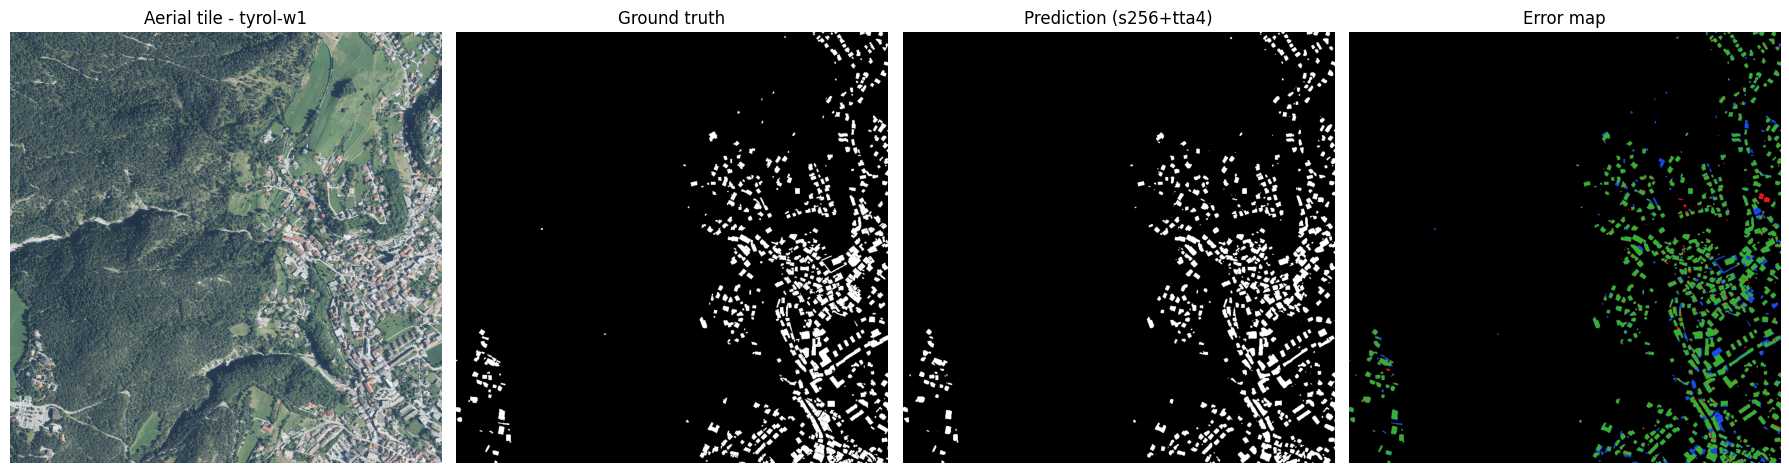

In [ ]:
if RUN_WHOLE_TILE_EVAL:
    tiles = ids_by_split["test"][:TILE_LIMIT]
    rows, demo = [], {}
    for mode in TILE_MODES:
        stride, tta = parse_mode(mode)
        stats = np.zeros(10)
        for tile_id in tiles:
            image, mask = read_image(tile_id), (read_mask(tile_id) > 127).astype(np.float32)
            prob = predict_tile(image, stride, tta)
            m = torch.from_numpy(mask).to(device).view(1, 1, *mask.shape)
            stats += confusion_and_boundary((prob >= BEST_THR).float().view(1, 1, *mask.shape), m, None, BOUNDARY_DILATION, BOUNDARY_TOL)[0].cpu().numpy()
            demo[(mode, tile_id)] = (image, mask, (prob >= BEST_THR).cpu().numpy())
        rows.append({"mode": mode, "tiles": len(tiles), "threshold": BEST_THR, **{k: v for k, v in summarize(stats).items() if k != "fg_fraction"}})
    tile_table = pd.DataFrame(rows).set_index("mode")
    display(tile_table[["tiles", "threshold", "iou", "dice", "precision", "recall", "boundary_iou", "boundary_f1"]].round(4))
    tile_table.to_csv(RESULTS_DIR / "whole_tile_modes.csv")

    # Whole-tile qualitative view (downsampled 5x): image | ground truth | prediction | error map
    mode, tile_id = TILE_MODES[-1], tiles[0]
    image, mask, pred = demo[(mode, tile_id)]
    truth, pred = mask > 0.5, pred > 0.5
    err = np.zeros((*truth.shape, 3)); err[truth & pred], err[~truth & pred], err[truth & ~pred] = (0.2, 0.7, 0.2), (0.9, 0.1, 0.1), (0.1, 0.3, 0.9)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
    for ax, data, name in zip(axes, [image[::5, ::5], truth[::5, ::5], pred[::5, ::5], err[::5, ::5]], ["Aerial tile", "Ground truth", f"Prediction ({mode})", "Error map"]):
        ax.imshow(data, cmap=None if data.ndim == 3 else "gray"); ax.set_title(f"{name} - {tile_id}" if name == "Aerial tile" else name); ax.axis("off")
    plt.tight_layout(); plt.savefig(RESULTS_DIR / "whole_tile_example.png", dpi=130); plt.show()
else:
    print("RUN_WHOLE_TILE_EVAL = False (skipped)")

## 10. Summary

- **Partitioning:** city-disjoint split (Austin/Chicago/Kitsap train, Vienna validation, West Tyrol test), non-overlapping patches created after the split, automated leakage audit passed.
- **Model:** SegFormer-B3 with an ImageNet-pretrained encoder (transfer learning), 47.2 M parameters.
- **Loss:** class-weighted BCE (positive weight 5.92) + Dice for the 14% building share; an edge-zone BCE fine-tune was tested and did not improve validation, so it was not adopted.
- **Metrics:** IoU, Dice, precision, recall, Boundary IoU, Boundary F1, ROC/PR-AUC; pixel accuracy reported only for reference; per-city and per-tile results.
- **Held-out test city (threshold 0.85 chosen on Vienna), full run:** IoU 0.775, Dice 0.873, Boundary F1 0.787 with overlapped inference plus TTA (IoU 0.7745 with non-overlapping windows).
- **Qualitative:** successes on high-contrast, straight-edged roofs; failures on white or pale non-building surfaces and low-contrast scenes; false alarms on very small objects and non-green fields.
- **Limitations:** a single held-out city and a single seed; no dedicated boundary term in the final loss; small inference-time gains (about one point of Boundary F1).

The numbers printed above come from this notebook's run; the paper's tables come from the full-length runs of the accompanying scripts (`train_segformer.py`, `test_segformer.py`, `evaluate_boundary.py`).